# Movie Review Sentiment Analysis using NLP
### Bag of Words (CountVectorizer) + Multinomial Naive Bayes

**Objective:** Classify movie reviews as Positive or Negative using a labelled movie-review dataset.

**Workflow:** Load data → preprocess text → CountVectorizer → train MultinomialNB → evaluate.

**Dataset:** NLTK Movie Reviews corpus (2,000 labelled reviews: positive and negative).

## 1. Install required libraries
Run this cell once. If Jupyter asks you to restart the kernel after installation, restart it and continue from the imports cell.

In [1]:
%pip install -q nltk scikit-learn pandas matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import re
import logging
from pathlib import Path

import joblib
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import movie_reviews
from nltk.stem import SnowballStemmer

from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Keep notebook output informative without unnecessary warnings.
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.


## 3. Download and load the labelled movie-review dataset

In [3]:
# Download the small NLTK movie_reviews corpus.
download_success = nltk.download("movie_reviews", quiet=True)

if not download_success:
    raise RuntimeError(
        "Could not download the NLTK Movie Reviews corpus. "
        "Check your internet connection and run this cell again."
    )

# Each file is one review; its category is either 'pos' or 'neg'.
records = []
for file_id in movie_reviews.fileids():
    label = movie_reviews.categories(file_id)[0]
    review_text = movie_reviews.raw(file_id)
    records.append({"review": review_text, "sentiment": label})

df = pd.DataFrame(records)

if df.empty or df[["review", "sentiment"]].isna().any().any():
    raise ValueError("The dataset is empty or contains missing review/label values.")

# Keep only the two expected sentiment classes.
df = df[df["sentiment"].isin(["pos", "neg"])].copy()
df["sentiment"] = df["sentiment"].map({"neg": "Negative", "pos": "Positive"})

print(f"Dataset shape: {df.shape}")
display(df.head())
print("\nClass distribution:")
display(df["sentiment"].value_counts())

Dataset shape: (2000, 2)


,review,sentiment
0,"plot : two teen couples go to a church party ,...",Negative
1,the happy bastard's quick movie review \ndamn ...,Negative
2,it is movies like these that make a jaded movi...,Negative
3,""" quest for camelot "" is warner bros . ' firs...",Negative
4,synopsis : a mentally unstable man undergoing ...,Negative



Class distribution:


sentiment
Negative    1000
Positive    1000
Name: count, dtype: int64

## 4. Explore the dataset

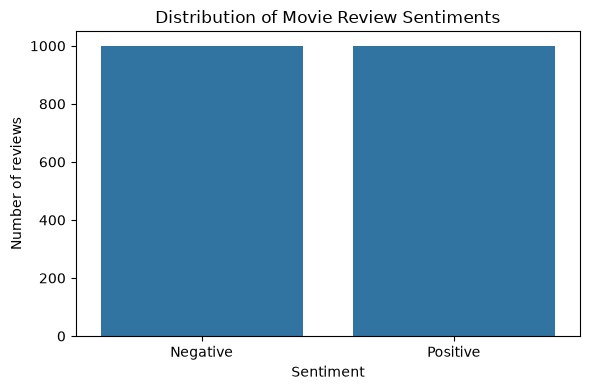

Number of reviews: 2000
Number of positive reviews: 1000
Number of negative reviews: 1000


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment", order=["Negative", "Positive"])
plt.title("Distribution of Movie Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

print("Number of reviews:", len(df))
print("Number of positive reviews:", (df["sentiment"] == "Positive").sum())
print("Number of negative reviews:", (df["sentiment"] == "Negative").sum())

## 5. Preprocess the text
The preprocessing function:
- converts text to lowercase;
- removes punctuation, numbers and other non-letter characters;
- removes English stop words while retaining **no**, **nor**, **not** and **never** because they can change sentiment;
- applies Snowball stemming to reduce words to their stems.

In [5]:
import re
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stemmer = SnowballStemmer("english")

# Retain negation words because they can change sentiment.
stop_words = set(ENGLISH_STOP_WORDS) - {"no", "nor", "not", "never"}

def preprocess_text(text):
    """Clean, tokenize, remove stop words, and stem a movie review."""
    if not isinstance(text, str):
        return ""

    text = text.lower()
    tokens = re.findall(r"\b[a-z]+\b", text)

    processed_tokens = [
        stemmer.stem(token)
        for token in tokens
        if token not in stop_words and len(token) > 1
    ]

    return " ".join(processed_tokens)


# Apply preprocessing
df["cleaned_review"] = df["review"].apply(preprocess_text)

# Handle empty reviews instead of stopping the notebook
empty_reviews = df["cleaned_review"].str.strip().eq("").sum()

if empty_reviews > 0:
    print(f"Removing {empty_reviews} empty reviews after preprocessing.")
    df = df.loc[df["cleaned_review"].str.strip().ne("")].copy()

# Reset index after removing empty reviews
df.reset_index(drop=True, inplace=True)

print("Text preprocessing completed successfully!")
print("Dataset shape after preprocessing:", df.shape)

display(df[["review", "cleaned_review", "sentiment"]].head(3))

Text preprocessing completed successfully!
Dataset shape after preprocessing: (2000, 3)


,review,cleaned_review,sentiment
0,"plot : two teen couples go to a church party ,...",plot teen coupl church parti drink drive accid...,Negative
1,the happy bastard's quick movie review \ndamn ...,happi bastard quick movi review damn bug got h...,Negative
2,it is movies like these that make a jaded movi...,movi like make jade movi viewer thank invent t...,Negative


## 6. Split the dataset into training and testing sets

In [ ]:
X = df["cleaned_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training reviews: {len(X_train)}")
print(f"Testing reviews:  {len(X_test)}")
print("\nTraining class distribution:")
display(y_train.value_counts())

## 7. Convert text into Bag-of-Words features using CountVectorizer
The vectorizer is fitted **only on training data** to prevent information leakage from the test set.

In [ ]:
vectorizer = CountVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_vectors = vectorizer.fit_transform(X_train)
X_test_vectors = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_vectors.shape)
print("Testing feature matrix: ", X_test_vectors.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

## 8. Train the Multinomial Naive Bayes classifier

In [ ]:
model = MultinomialNB(alpha=0.5)
model.fit(X_train_vectors, y_train)

print("Multinomial Naive Bayes model trained successfully.")

## 9. Make predictions on the test data

In [ ]:
y_pred = model.predict(X_test_vectors)

results = pd.DataFrame({
    "Actual Sentiment": y_test.reset_index(drop=True),
    "Predicted Sentiment": pd.Series(y_pred)
})

display(results.head(10))

## 10. Evaluate model accuracy and classification metrics

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Negative", "Positive"],
        zero_division=0
    )
)

## 11. Display the confusion matrix

In [ ]:
labels = ["Negative", "Positive"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix - Movie Review Sentiment Analysis")
plt.tight_layout()
plt.show()

print("Confusion matrix values:")
print(cm)

## 12. Test the model with your own movie reviews

In [ ]:
def predict_sentiment(review):
    """Return the predicted sentiment and class probabilities for a review."""
    if not isinstance(review, str) or not review.strip():
        raise ValueError("Please enter a non-empty movie review.")

    cleaned_review = preprocess_text(review)
    review_vector = vectorizer.transform([cleaned_review])
    prediction = model.predict(review_vector)[0]
    probabilities = model.predict_proba(review_vector)[0]
    probability_by_class = dict(zip(model.classes_, probabilities))

    return prediction, probability_by_class

sample_reviews = [
    "This movie was fantastic, entertaining and beautifully acted.",
    "The movie was boring, disappointing and a complete waste of time.",
    "I did not enjoy this film because the story was weak."
]

for review in sample_reviews:
    sentiment, probabilities = predict_sentiment(review)
    print(f"Review: {review}")
    print(f"Predicted sentiment: {sentiment}")
    print(
        "Probabilities:",
        {label: f"{probability:.3f}" for label, probability in probabilities.items()}
    )
    print("-" * 70)

## 13. Save the trained model and vectorizer

In [ ]:
output_dir = Path("sentiment_model")
output_dir.mkdir(parents=True, exist_ok=True)

model_path = output_dir / "multinomial_nb_model.joblib"
vectorizer_path = output_dir / "count_vectorizer.joblib"

joblib.dump(model, model_path)
joblib.dump(vectorizer, vectorizer_path)

print(f"Model saved to: {model_path.resolve()}")
print(f"Vectorizer saved to: {vectorizer_path.resolve()}")

## 14. Conclusion

In this project, a movie-review sentiment analysis system was developed using Natural Language Processing. The labelled Movie Reviews dataset was cleaned using lowercase conversion, stop-word removal and stemming. CountVectorizer converted the preprocessed reviews into Bag-of-Words numerical features. A Multinomial Naive Bayes classifier was trained to predict whether a review was Positive or Negative.

The model was evaluated using accuracy, a classification report and a confusion matrix. It was also tested on new sample reviews. The trained classifier and vectorizer were saved for future use.

**Final test accuracy:** The actual accuracy is displayed in Section 10 after running the notebook. Do not write a guessed accuracy in your report.